# Warehouse2: large agents cannot use the shelf gaps

Two radius-0.70 agents cross narrow aisles between square shelves. A radius-0.30 agent could travel directly through those aisles; RRT-Connect sends the larger agents through wider corridors. The obstacles shaded red include the robot radius and a 0.15 safety margin.

![Large-agent warehouse run](rrt_connect_warehouse2_large_agents.gif)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display
from shapely.geometry import LineString, Polygon
from shapely.ops import unary_union

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())
world = suite['worlds']['warehouse2']
obstacles, bounds = world['obstacles'], world['bounds']

## Passage width and agent size

The starts and goals are editable three-component poses. Both straight lines cross narrow horizontal openings between rows of square shelves. The upper opening is measured from the map geometry; the second is similar. A robot needs at least twice its radius plus the planning margin to fit.

In [2]:
SMALL_RADIUS, LARGE_RADIUS, CLEARANCE = 0.30, 0.70, 0.15
SEED = 42
AGENT_NAMES = ['upper narrow aisle', 'middle narrow aisle']
CUSTOM_STARTS = np.array([[84.0, -16.32, 0.0], [84.0, -32.37, 0.0]])
CUSTOM_GOALS = np.array([[116.0, -16.32, 0.0], [116.0, -32.37, 0.0]])
if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.shape != (len(AGENT_NAMES), 3):
    raise ValueError('Starts and goals must have one [x, y, theta] row per agent')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Starts and goals must be finite')

# These fixed square-shelf indices face each other across the upper aisle.
upper_shelf_bottom = Polygon(obstacles[38]).bounds[1]
lower_shelf_top = Polygon(obstacles[22]).bounds[3]
gap_width = upper_shelf_bottom - lower_shelf_top
small_required = 2 * (SMALL_RADIUS + CLEARANCE)
large_required = 2 * (LARGE_RADIUS + CLEARANCE)
print(f'Gap width: {gap_width:.3f}; small required: {small_required:.3f}; large required: {large_required:.3f}')
assert small_required < gap_width < large_required

def make_planner(radius, seed):
    return RRTConnectPlanner(
        obstacles, bounds, robot_radius=radius, clearance=CLEARANCE,
        step_size=0.8, max_iterations=15_000,
        smoothing_iterations=400, seed=seed,
    )

small_planner = make_planner(SMALL_RADIUS, SEED)
large_planners = [make_planner(LARGE_RADIUS, SEED + i) for i in range(len(AGENT_NAMES))]
planning_results = []
for i, (start, goal, planner) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS, large_planners)):
    small_direct = small_planner.segment_is_free(start[:2], goal[:2])
    large_direct = planner.segment_is_free(start[:2], goal[:2])
    assert small_direct and not large_direct, 'Chosen route no longer demonstrates the size difference'
    result = planner.plan(start[:2], goal[:2])
    assert all(planner.segment_is_free(a, b) for a, b in zip(result.path, result.path[1:]))
    planning_results.append(result)
    length = sum(np.linalg.norm(np.subtract(a, b)) for a, b in zip(result.path, result.path[1:]))
    print(f'{AGENT_NAMES[i]}: small direct={small_direct}, large direct={large_direct}, '
          f'large anchor length={length:.2f}, vertices={len(result.path)}')
anchor_paths = [result.path for result in planning_results]

Gap width: 1.155; small required: 0.900; large required: 1.700
upper narrow aisle: small direct=True, large direct=False, large anchor length=42.17, vertices=6
middle narrow aisle: small direct=True, large direct=False, large anchor length=49.36, vertices=6


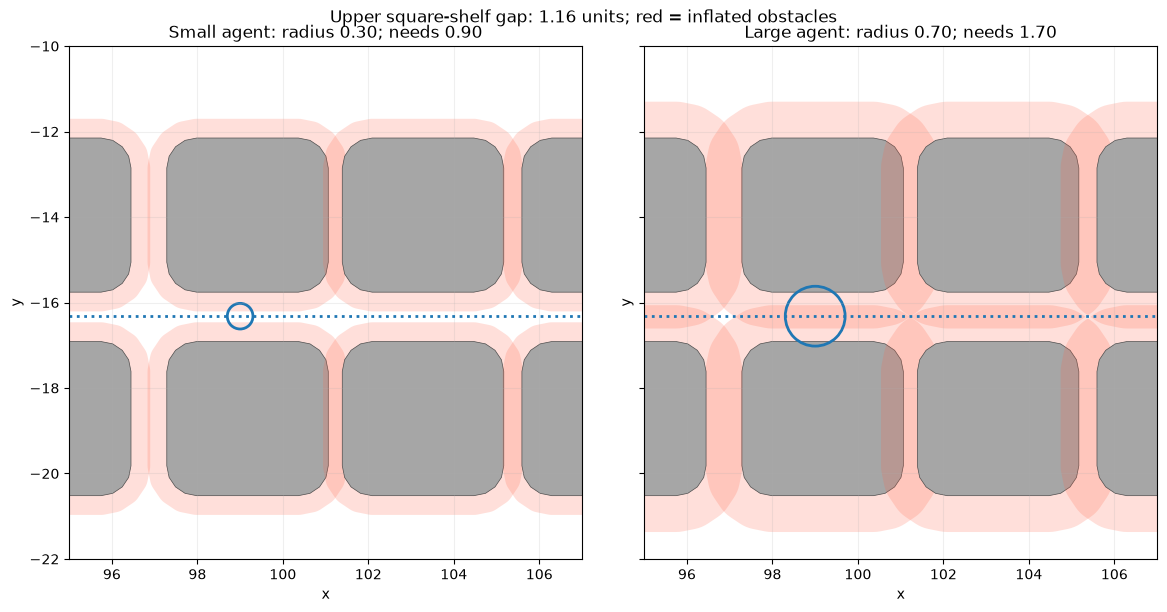

In [3]:
def draw_shelves(ax, radius=None, view=(75, 120, -44, -8)):
    xmin, xmax, ymin, ymax = view
    for vertices in obstacles:
        polygon = Polygon(vertices)
        x0, y0, x1, y1 = polygon.bounds
        if x1 < xmin or x0 > xmax or y1 < ymin or y0 > ymax:
            continue
        if radius is not None:
            inflated = polygon.buffer(radius + CLEARANCE)
            ax.add_patch(PolygonPatch(np.asarray(inflated.exterior.coords),
                                      facecolor='tomato', edgecolor='none', alpha=0.20))
        ax.add_patch(PolygonPatch(vertices, facecolor='0.65', edgecolor='0.3', linewidth=0.5))
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, radius, label in zip(axes, [SMALL_RADIUS, LARGE_RADIUS], ['Small agent', 'Large agent']):
    draw_shelves(ax, radius=radius, view=(95, 107, -22, -10))
    ax.axhline(CUSTOM_STARTS[0, 1], color='tab:blue', linestyle=':', linewidth=2)
    ax.add_patch(Circle((99.0, CUSTOM_STARTS[0, 1]), radius, fill=False,
                        edgecolor='tab:blue', linewidth=2))
    ax.set_title(f'{label}: radius {radius:.2f}; needs {2 * (radius + CLEARANCE):.2f}')
fig.suptitle(f'Upper square-shelf gap: {gap_width:.2f} units; red = inflated obstacles')
plt.tight_layout()
plt.show()

## Run both large agents with ORCA-MPPI

The controller uses the same radius as RRT. A heading cost points each agent along its anchor, a small cost discourages steering changes, and an angular-acceleration limit bounds steering changes in every sampled rollout and executed step. The run reports the maximum per-step change to verify that limit. Executed trajectories can still deviate from the anchors.

In [4]:
AGENTS_NUM = len(AGENT_NAMES)
DT = 0.1
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 2))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 2))]
agent_params = {
    AGENT_SIZE: LARGE_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: 8.0, DIFF_DRIVE_V_MIN: -0.01,
    DIFF_DRIVE_W_MAX: 5.0, DIFF_DRIVE_W_MIN: -5.0,
    DIFF_DRIVE_W_ACCEL_MAX: 10.0,
}
agents_params = [agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.DiffDriveDyn() for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 200, SAMPLE_TIME_STEPS: 15, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    CONTROL_COV: np.diag([25.0, 16.0]),
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: False,
    K_ALPHA: -2.96, RAD_EPS: 0.05, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 2000.0,
    ANCHOR_HEADING_WEIGHT: 500.0, CONTROL_SMOOTHNESS_WEIGHT: 20.0,
}
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 0.7, MAX_EXP_STEPS: 350}
expanded_bounds = np.asarray(bounds) + np.array([-1, -1, 1, 1]) * (LARGE_RADIUS + 0.05)
controller_obstacles = obstacles + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
goal_errors = np.linalg.norm(states[-1, :, :2] - goal_states[:, :2], axis=1)
turn_rates = np.diff(states[:, :, 2], axis=0) / DT
max_turn_change = np.max(np.abs(np.diff(turn_rates, axis=0)), axis=0)
obstacle_union = unary_union([Polygon(vertices) for vertices in obstacles])
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
for name, error, path, turn_change in zip(AGENT_NAMES, goal_errors, anchor_paths, max_turn_change):
    surface_clearance = LineString(path).distance(obstacle_union) - LARGE_RADIUS
    print(f'{name}: final XY error={error:.3f}, anchor surface clearance={surface_clearance:.3f}, '
          f'max turn-rate change per step={turn_change:.3f}')

success=True, collisions=0.0, steps=114, wall time=16.47s
upper narrow aisle: final XY error=0.220, anchor surface clearance=0.166
middle narrow aisle: final XY error=0.499, anchor surface clearance=0.188


## Planned and executed routes

Gray dotted lines are direct paths available to the small agent. Dashed colored lines are the large agents' anchors; solid lines are their executed trajectories.

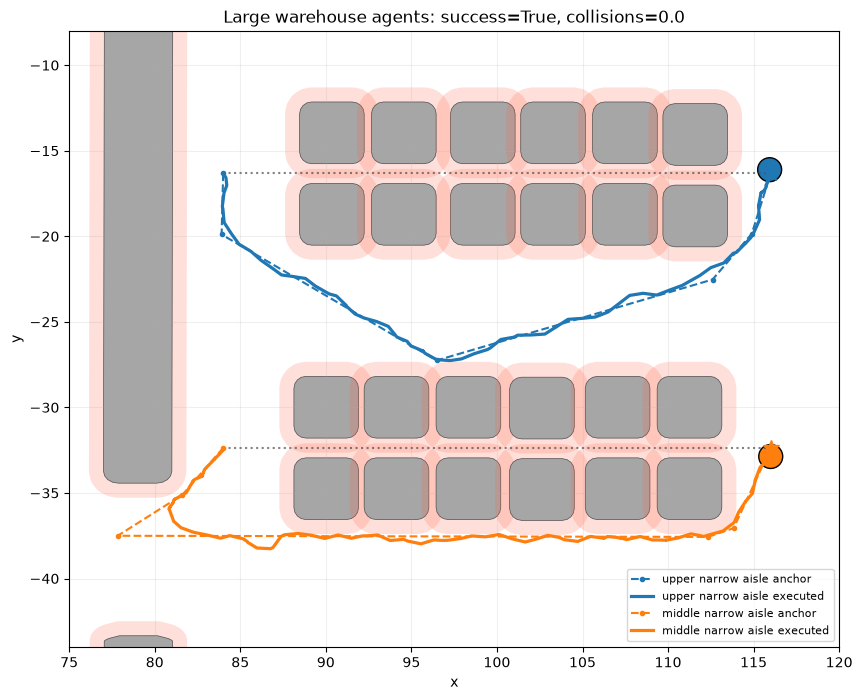

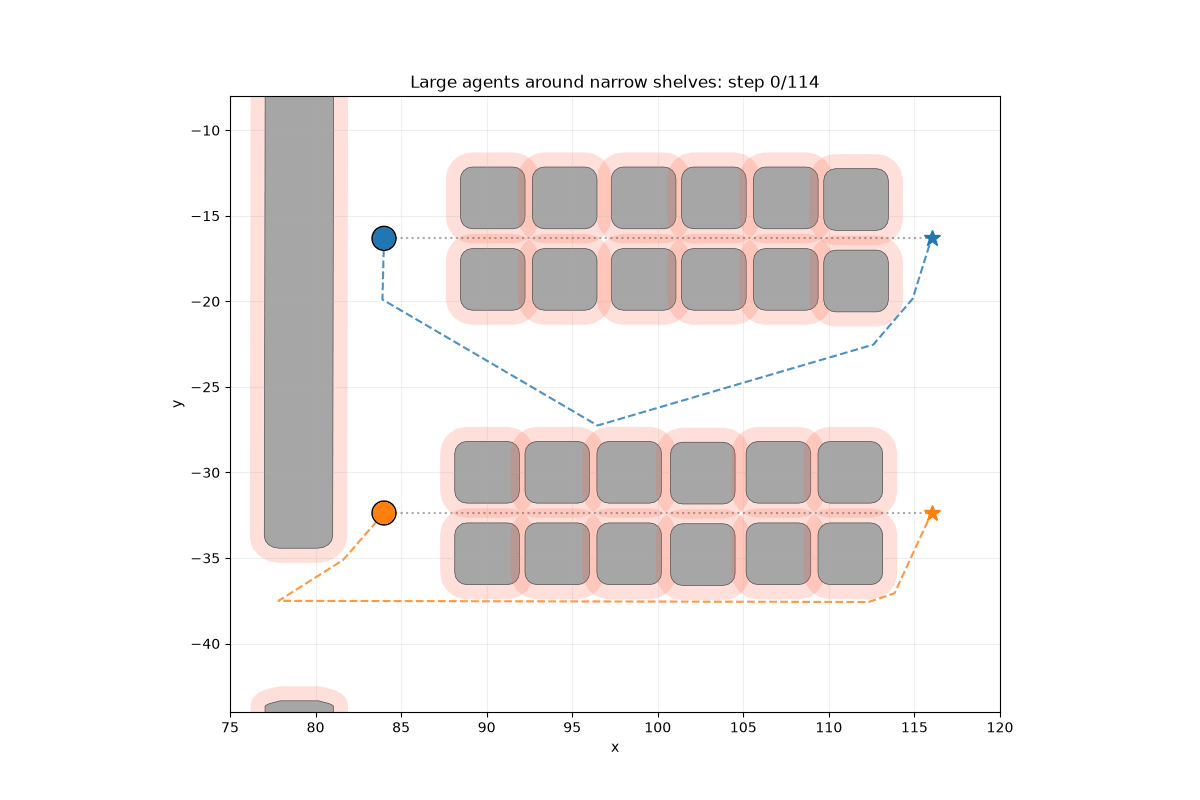

In [5]:
colors = plt.colormaps['tab10'](np.arange(AGENTS_NUM))
fig, ax = plt.subplots(figsize=(12, 8))
draw_shelves(ax, radius=LARGE_RADIUS)
for i, (name, start, goal, path) in enumerate(zip(AGENT_NAMES, CUSTOM_STARTS, CUSTOM_GOALS, anchor_paths)):
    anchor = np.asarray(path)
    ax.plot([start[0], goal[0]], [start[1], goal[1]], ':', color='0.3', alpha=0.7)
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=colors[i], markersize=3, label=f'{name} anchor')
    ax.plot(states[:, i, 0], states[:, i, 1], '-', color=colors[i], linewidth=2.3, label=f'{name} executed')
    ax.add_patch(Circle(states[-1, i, :2], LARGE_RADIUS, facecolor=colors[i], edgecolor='black'))
    ax.plot(*goal[:2], '*', color=colors[i], markersize=12)
ax.set_title(f'Large warehouse agents: success={success}, collisions={collisions}')
ax.legend(loc='lower right', fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
draw_shelves(ax, radius=LARGE_RADIUS)
trails, robots = [], []
for i, (start, goal, path) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS, anchor_paths)):
    anchor = np.asarray(path)
    ax.plot([start[0], goal[0]], [start[1], goal[1]], ':', color='0.35', alpha=0.5)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=colors[i], alpha=0.8)
    ax.plot(*goal[:2], '*', color=colors[i], markersize=12)
    trail, = ax.plot([], [], '-', color=colors[i], linewidth=2.5)
    robot = Circle(states[0, i, :2], LARGE_RADIUS, facecolor=colors[i], edgecolor='black', zorder=5)
    ax.add_patch(robot)
    trails.append(trail)
    robots.append(robot)
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(120, len(states))).astype(int))

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    for i, (trail, robot) in enumerate(zip(trails, robots)):
        trail.set_data(states[:state_index + 1, i, 0], states[:state_index + 1, i, 1])
        robot.center = states[state_index, i, :2]
    ax.set_title(f'Large agents around narrow shelves: step {state_index}/{len(states) - 1}')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = ROOT / 'benchmarks/rrt_connect_warehouse2_large_agents.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))